# Explicabilidad con Grad-CAM

Experimentos con los modelos finales YOLO11n y YOLO11s (`configuracion_final.json`), semilla 42.
Toda foto nueva pasa por el preprocesamiento del dataset (`comun.preprocesar`, con normalización fotométrica);
las imágenes de `Data_final` ya están preprocesadas.
Se explica el **logit de la clase predicha de una candidata anterior al NMS**.
Los mapas no explican directamente el conteo ni la regresión de la caja.

Este notebook contiene la configuración, las comprobaciones, los mapas por grano,
la comparación entre capas, la concentración por área y las pruebas de eliminación
e inserción. Las tablas y figuras quedan dentro del notebook; no se generan carpetas de salida.
Reinicia el kernel antes de ejecutar todo. Cambia `ESCENAS` para incorporar otras fotos
propias con sus etiquetas de referencia, sin seleccionar a posteriori el peor caso de valid.

La sección 7 añade una prueba reproducible con imágenes de `valid`; el test se reserva para la evaluación final.

In [1]:
import os
import sys
import tempfile
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import importlib.metadata

sys.dont_write_bytecode = True
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'matplotlib-gradcam'))
os.environ['YOLO_VERBOSE'] = 'False'
CARPETA = Path.cwd() if (Path.cwd() / 'cam_yolo.py').is_file() else Path.cwd() / 'explicabilidad'
sys.path.insert(0, str(CARPETA.resolve()))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display, JSON
from ultralytics import YOLO
import cam_yolo as K

torch.set_num_threads(4)
MODELOS = ('yolo11n', 'yolo11s')
ESCENAS = ('imgMixta',)  # También: imgArrugados, imgTest3.
SEMILLA = 42
OBJETIVO = 'logit'  # Alternativas: 'probabilidad', 'margen'; cambian la pregunta explicada.
FRACCIONES = (0., .1, .3, .5, 1.)
ALEATORIOS, TAM_BLOQUE, SIGMA = 3, 32, 8.
EJECUTAR_ESCENA = False
EJECUTAR_CONTEXTO = False
CLASE = {0: 'Healthy', 1: 'Defect'}
CFG = K.E.configuracion('final')

DET, PREP, CASOS, MAPAS = {}, {}, [], {}
print('Dispositivo:', 'cuda' if torch.cuda.is_available() else 'cpu')

Dispositivo: cuda


## 1. Comprobaciones básicas

Se comprueba que el emparejamiento conserve caja, clase y confianza, que la referencia
uniforme tenga enriquecimiento 1 y que las máscaras oculten la misma cantidad de píxeles.

In [2]:
a = {'cajas': np.array([[0., 0., 1., 1.], [10., 10., 11., 11.]]),
     'clases': np.array([0, 1]), 'conf': np.array([.8, .9])}
b = {**a, 'cajas': np.array([[0., 10., 1., 11.], [10., 0., 11., 1.]])}
assert not K.comparar_detecciones(a, b)['equivalentes']
assert K.comparar_detecciones(a, {k: v[::-1] for k, v in a.items()})['equivalentes']
uniforme = K.concentracion(np.ones((10, 10)), np.array([[0, 0, 2, 2]]), np.array([0]), 0)
assert np.isclose(uniforme['propia'], .04) and np.isclose(uniforme['enriquecimiento_propia'], 1)
dominio_prueba = np.ones((7, 9), bool)
unidades = K.bloques(dominio_prueba, 4)
areas = [[m.sum() for _, _, m in K.mascaras_area((7, 9), unidades, orden, FRACCIONES)]
         for orden in [np.arange(len(unidades)), np.arange(len(unidades))[::-1]]]
assert areas[0] == areas[1]
print('Comparación por IoU, referencia uniforme e igualdad de área: OK')

Comparación por IoU, referencia uniforme e igualdad de área: OK


## 2. Detecciones, inventario y trazabilidad

Se comparan las detecciones con `predict`, usando las mismas condiciones de inferencia.
El inventario registra aciertos, cambios de clase, no detectados y sobrantes.
Para el piloto se elige el primer acierto, el primer error de clase y el primer sobrante
de cada modelo/escena, si existen. Los no detectados se conservan en el inventario:
no tienen una detección final cuyo CAM se pueda explicar.

In [3]:
inventarios, comparaciones = [], []
manifiesto = {'fecha': datetime.now(ZoneInfo('America/Guayaquil')).isoformat(),
              'dispositivo': 'cuda' if torch.cuda.is_available() else 'cpu',
              'versiones': {n: importlib.metadata.version(n) for n in
                            ('torch', 'ultralytics', 'grad-cam', 'numpy', 'opencv-python', 'scipy')},
              'codigo_sha256': K.sha256(Path(K.__file__)), 'modelos': {}, 'imagenes': {},
              'protocolo': {'semilla': SEMILLA, 'escenas': ESCENAS, 'objetivo': OBJETIVO,
                            'fracciones': FRACCIONES, 'controles': ALEATORIOS,
                            'bloque': TAM_BLOQUE, 'sigma': SIGMA, 'capas': K.CAPAS}, 'casos': []}
for modelo in MODELOS:
    pesos = next(p for p in CFG[modelo]['pesos'] if f'_s{SEMILLA}_' in str(p))
    d = K.Detector(pesos, CFG[modelo]['conf_conteo'])
    DET[modelo] = d
    manifiesto['modelos'][modelo] = {'pesos': str(pesos), 'sha256': K.sha256(pesos),
                                     'conf': d.conf, 'imgsz': d.imgsz, 'iou_nms': d.iou, 'agnostic_nms': True}
    for escena in ESCENAS:
        img, ref, cl = K.cargar_foto(escena)
        x, rgb, t = d.preparar(img)
        det = d.detectar(x)
        refs = K.a_letterbox(ref, t)
        dominio = K.dominio_imagen(rgb.shape[:2], img.shape[:2], t)
        filas = K.inventario(refs, cl, det)
        PREP[modelo, escena] = dict(img=img, x=x, rgb=rgb, t=t, det=det, ref=refs,
                                    cl=cl, dominio=dominio, inventario=filas)
        inventarios.extend({'modelo': modelo, 'escena': escena, **r} for r in filas)
        r = YOLO(str(pesos)).predict(np.ascontiguousarray(rgb[..., ::-1]), imgsz=d.imgsz, conf=d.conf, iou=d.iou,
                                    agnostic_nms=True, device=d.dispositivo, verbose=False)[0]
        otro = {'cajas': r.boxes.xyxy.cpu().numpy(),
                'clases': r.boxes.cls.cpu().numpy().astype(int), 'conf': r.boxes.conf.cpu().numpy()}
        comparaciones.append({'modelo': modelo, 'escena': escena, **K.comparar_detecciones(det, otro)})
        archivo = K.E.FOTOS / 'propias' / f'{escena}.jpeg'
        manifiesto['imagenes'][escena] = {'ruta': str(archivo), 'sha256': K.sha256(archivo),
                                        'referencia_sha256': K.sha256(archivo.parent / 'referencia' / f'{escena}.txt')}
        for estado in ('acierto', 'clase cambiada', 'sobrante'):
            registro = next((r for r in filas if r['estado'] == estado), None)
            if registro is None:
                continue
            q = registro['prediccion']
            caso = dict(modelo=modelo, escena=escena, **registro,
                        id=f'{modelo}_{escena}_pred{q}', indice=int(det['indices'][q]),
                        clase=int(det['clases'][q]), capa=str(det['nivel'][q]),
                        caja=det['cajas'][q].tolist(), forma_tensor=list(x.shape))
            CASOS.append(caso)
manifiesto['casos'] = CASOS
inventario = pd.DataFrame(inventarios)
comparacion_predict = pd.DataFrame(comparaciones)
display(comparacion_predict)
display(inventario.groupby(['modelo', 'escena', 'estado']).size().rename('n').to_frame())
display(JSON(manifiesto, expanded=False))

,modelo,escena,parejas,sin_pareja_a,sin_pareja_b,mismas_clases_pareadas,min_iou,max_diferencia_caja_px,max_diferencia_conf,equivalentes
0,yolo11n,imgMixta,15,0,0,True,0.999579,0.010376,0.001021,False
1,yolo11s,imgMixta,15,0,0,True,0.999884,0.004883,0.000571,False


n
modelo  escena   estado           
yolo11n imgMixta acierto         8
                 clase cambiada  7
yolo11s imgMixta acierto         8
                 clase cambiada  7

<IPython.core.display.JSON object>

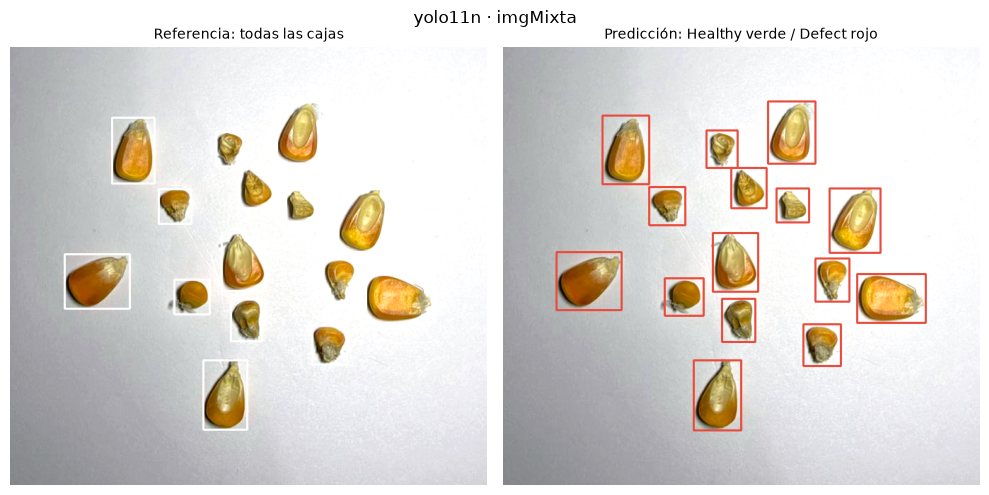

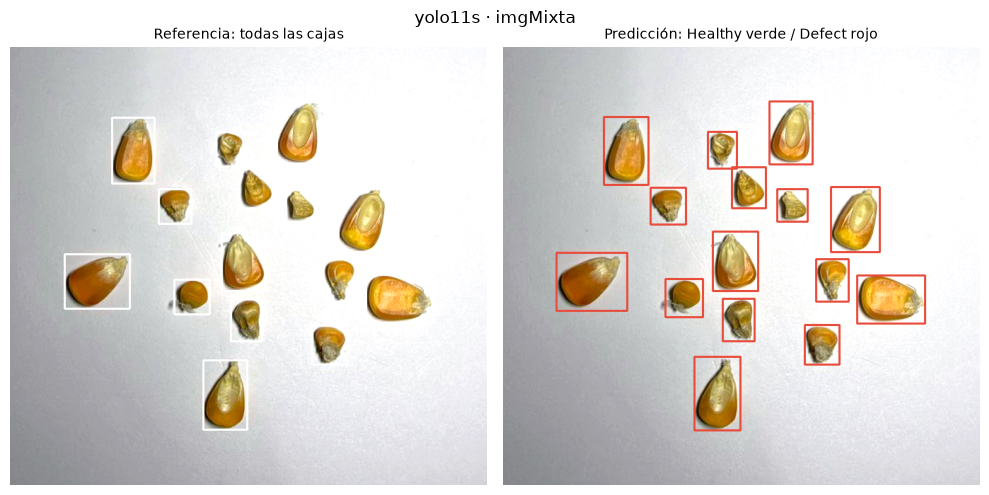

In [4]:
def vista(ax, imagen, p, titulo, recortar=True):
    ax.imshow(imagen)
    if recortar and len(p['ref']):
        lo, hi = p['ref'][:, :2].min(0), p['ref'][:, 2:].max(0)
        margen = max(hi - lo) * .15
        h, w = imagen.shape[:2]
        ax.set_xlim(max(0, lo[0] - margen), min(w, hi[0] + margen))
        ax.set_ylim(min(h, hi[1] + margen), max(0, lo[1] - margen))
    ax.set_title(titulo, fontsize=10)
    ax.axis('off')

for (modelo, escena), p in PREP.items():
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    pred = p['rgb'].copy()
    for clase, color in [(0, K.E.CAJA_OK), (1, K.E.CAJA_MAL)]:
        pred = K.E.dibujar(pred, p['det']['cajas'][p['det']['clases'] == clase], color)
    vista(axes[0], K.E.dibujar(p['rgb'], p['ref'], (255, 255, 255)), p, 'Referencia: todas las cajas')
    vista(axes[1], pred, p, 'Predicción: Healthy verde / Defect rojo')
    fig.suptitle(f'{modelo} · {escena}')
    plt.tight_layout(); plt.show()

## 3. Grad-CAM por grano y comparación de capas

El recuadro blanco identifica la detección explicada. Se comparan la salida del cuello
que entra a `Detect` (P3, P4 o P5 según la candidata) y la salida B3 del backbone.
El encuadre de las figuras facilita la lectura; el cálculo utiliza la imagen completa,
sin recortar ni forzar el mapa a la caja. Los mapas de varias detecciones pueden resaltar
regiones parecidas por la ponderación global de canales de Grad-CAM.

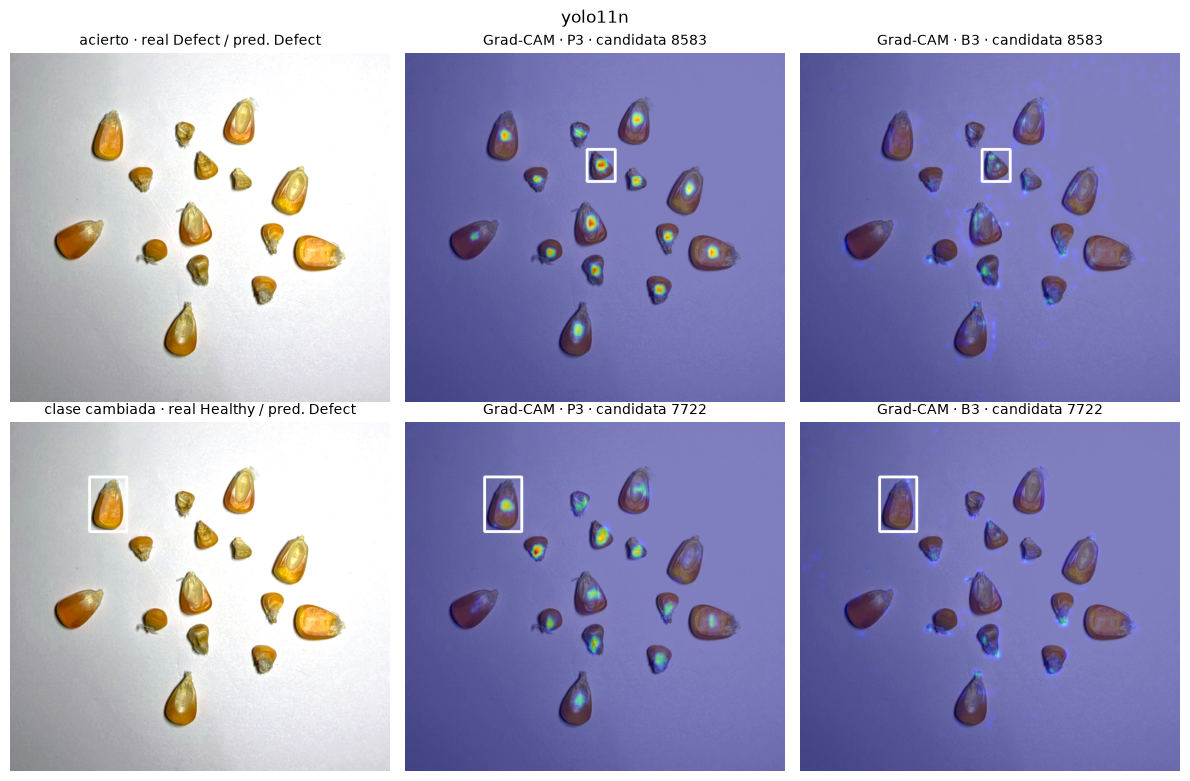

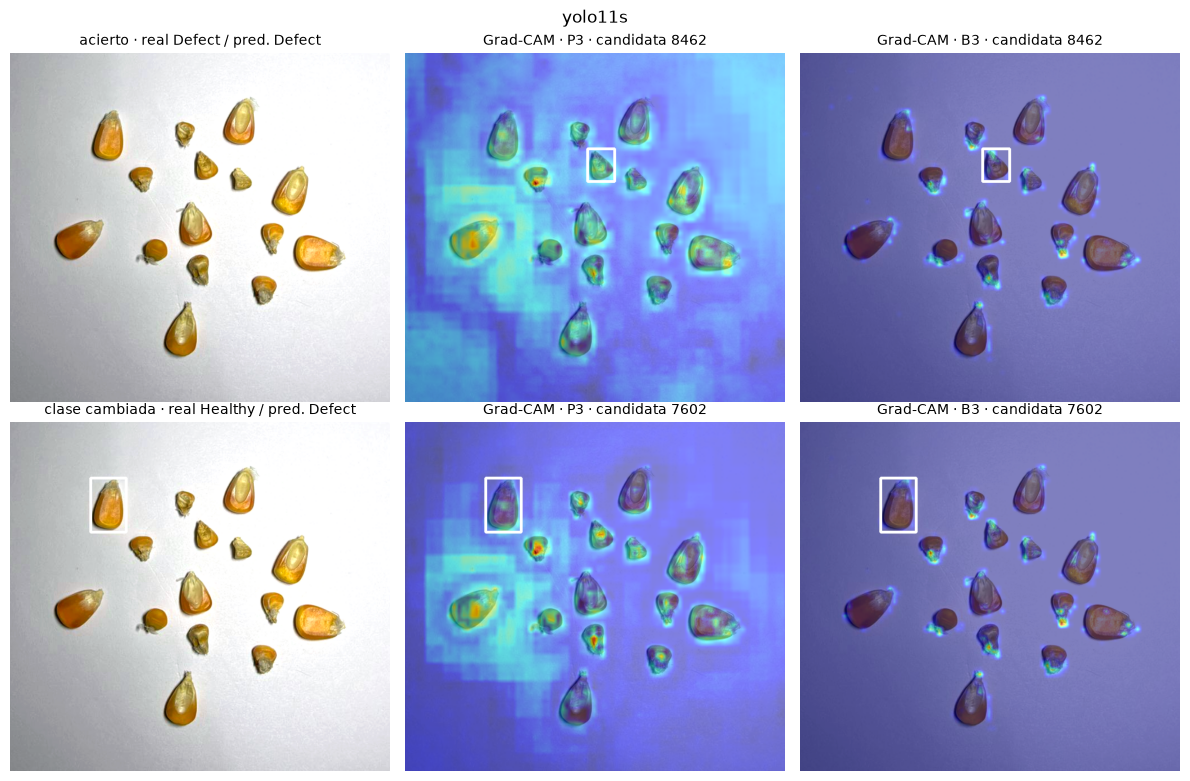

In [5]:
for modelo in MODELOS:
    seleccion = [c for c in CASOS if c['modelo'] == modelo]
    if not seleccion:
        continue
    fig, axes = plt.subplots(len(seleccion), 3, figsize=(12, 4 * len(seleccion)), squeeze=False)
    for fila, caso in zip(axes, seleccion):
        p, d = PREP[modelo, caso['escena']], DET[modelo]
        caja = np.asarray(caso['caja'])[None]
        referencia = 'sin referencia' if caso['referencia'] is None else CLASE[caso['referencia']]
        vista(fila[0], K.E.dibujar(p['rgb'], caja, (255, 255, 255), 3), p,
              f"{caso['estado']} · real {referencia} / pred. {CLASE[caso['clase']]}")
        for ax, capa in zip(fila[1:], (caso['capa'], 'B3')):
            mapa = d.mapa(p['x'], [capa], [caso['indice']], caso['clase'], objetivo=OBJETIVO)
            assert np.isfinite(mapa).all() and (mapa >= 0).all()
            MAPAS[caso['id'], capa] = mapa
            imagen = K.E.dibujar(K.superponer(p['rgb'], mapa), caja, (255, 255, 255), 3)
            vista(ax, imagen, p, f"Grad-CAM · {capa} · candidata {caso['indice']}")
    fig.suptitle(modelo)
    plt.tight_layout(); plt.show()

## 4. Concentración espacial y referencia uniforme

Se compara la masa del mapa con el área de cada región: caja propia, otras cajas de la
misma clase de referencia, cajas de otra clase y fondo. Se excluye el relleno de letterbox.
Un enriquecimiento de 1 corresponde al mapa uniforme. Las regiones superpuestas no se
cuentan dos veces; un mapa nulo se registra con NaN. Estas medidas describen concentración,
no porcentajes de causalidad. Para sobrantes se indica que la caja es predicha.

In [6]:
filas = []
for caso in CASOS:
    p = PREP[caso['modelo'], caso['escena']]
    g = caso['grano']
    cajas, clases, gi = ((p['ref'], p['cl'], g) if g is not None
                         else (np.asarray(caso['caja'])[None], np.array([caso['clase']]), 0))
    for capa in (caso['capa'], 'B3'):
        mapa = MAPAS[caso['id'], capa]
        filas.append({'caso': caso['id'], 'estado': caso['estado'], 'capa': capa,
                      'cajas': 'referencia' if g is not None else 'predichas',
                      'mapa_plano': bool(np.ptp(mapa) < 1e-7),
                      **K.concentracion(mapa, cajas, clases, gi, p['dominio'])})
concentracion = pd.DataFrame(filas)
display(concentracion.round(5))

,caso,estado,capa,cajas,mapa_plano,propia,area_propia,enriquecimiento_propia,misma clase,area_misma clase,enriquecimiento_misma clase,otra clase,area_otra clase,enriquecimiento_otra clase,fondo,area_fondo,enriquecimiento_fondo
0,yolo11n_imgMixta_pred0,acierto,P3,referencia,False,0.08827,0.00214,41.21103,0.39986,0.01339,29.86702,0.50661,0.03376,15.00545,0.00527,0.95071,0.00554
1,yolo11n_imgMixta_pred0,acierto,B3,referencia,False,0.04508,0.00214,21.04519,0.18732,0.01339,13.99195,0.33134,0.03376,9.81416,0.43626,0.95071,0.45888
2,yolo11n_imgMixta_pred2,clase cambiada,P3,referencia,False,0.08777,0.00454,19.32747,0.29138,0.02922,9.97168,0.57129,0.01553,36.78670,0.04957,0.95071,0.05214
3,yolo11n_imgMixta_pred2,clase cambiada,B3,referencia,False,0.04098,0.00454,9.02374,0.24613,0.02922,8.42335,0.29735,0.01553,19.14685,0.41554,0.95071,0.43709
4,yolo11s_imgMixta_pred4,acierto,P3,referencia,False,0.00360,0.00214,1.68065,0.02147,0.01339,1.60353,0.05575,0.03376,1.65142,0.91918,0.95071,0.96683
5,yolo11s_imgMixta_pred4,acierto,B3,referencia,False,0.04206,0.00214,19.63643,0.31511,0.01339,23.53677,0.31950,0.03376,9.46340,0.32334,0.95071,0.34010
6,yolo11s_imgMixta_pred9,clase cambiada,P3,referencia,False,0.00841,0.00454,1.85248,0.06472,0.02922,2.21506,0.04484,0.01553,2.88746,0.88202,0.95071,0.92775
7,yolo11s_imgMixta_pred9,clase cambiada,B3,referencia,False,0.04084,0.00454,8.99297,0.27911,0.02922,9.55178,0.43962,0.01553,28.30834,0.24043,0.95071,0.25290


## 5. Eliminación e inserción con controles aleatorios

Se ordenan bloques de 32 píxeles por su media CAM en toda la imagen válida. Se reemplazan
por un desenfoque (eliminación) o se restauran desde esa base (inserción). Tres órdenes
aleatorios usan exactamente la misma área y preservan el relleno. Se evalúa la capa que
produjo la candidata, elegida antes de observar las curvas.

Se registran logit, probabilidad, IoU y puntuación de la candidata fija, junto con
`máx(IoU con caja original × p de la clase objetivo)` entre candidatas pre-NMS.
Esta puntuación reasociada es un indicador operativo del experimento, no una métrica
publicada reproducida exactamente ni una evaluación del conteo. La ejecución tarda
varios minutos en CPU. Cambia las fracciones o los controles en la configuración inicial.

In [7]:
resultados = []
for caso in CASOS:
    p = PREP[caso['modelo'], caso['escena']]
    tabla = K.perturbaciones(DET[caso['modelo']], p['x'], p['rgb'], p['dominio'], caso,
                             MAPAS[caso['id'], caso['capa']], fracciones=FRACCIONES,
                             aleatorios=ALEATORIOS, tam_bloque=TAM_BLOQUE,
                             sigma=SIGMA, semilla=SEMILLA)
    tabla.insert(0, 'caso', caso['id'])
    resultados.append(tabla)
    print('Completado:', caso['id'], caso['estado'])
curvas = pd.concat(resultados, ignore_index=True) if resultados else pd.DataFrame()
if len(curvas):
    assert curvas.groupby(['caso', 'fraccion']).area_real.nunique().eq(1).all()
    assert np.isfinite(curvas.select_dtypes('number')).all().all()
    for _, grupo in curvas.groupby('caso'):
        original = grupo[((grupo.modo == 'eliminacion') & (grupo.fraccion == 0)) |
                         ((grupo.modo == 'insercion') & (grupo.fraccion == 1))]
        assert original.score_reasociado.nunique() == 1
    print(len(curvas), 'mediciones; igualdad de área, finitud y extremos: OK')
else:
    print('No hay detecciones seleccionadas para evaluar.')

Completado: yolo11n_imgMixta_pred0 acierto


Completado: yolo11n_imgMixta_pred2 clase cambiada


Completado: yolo11s_imgMixta_pred4 acierto


Completado: yolo11s_imgMixta_pred9 clase cambiada
160 mediciones; igualdad de área, finitud y extremos: OK


,caso,metodo,control,modo,auc,auc_normalizada,media_aleatoria,de_aleatoria,diferencia_frente_aleatorio
0,yolo11n_imgMixta_pred0,Grad-CAM,-1,eliminacion,0.1419,0.1634,0.6971,0.1329,-0.5337
1,yolo11n_imgMixta_pred0,Grad-CAM,-1,insercion,0.7974,0.9185,0.5755,0.1250,0.3430
8,yolo11n_imgMixta_pred2,Grad-CAM,-1,eliminacion,0.1896,0.2223,0.5698,0.2298,-0.3475
9,yolo11n_imgMixta_pred2,Grad-CAM,-1,insercion,0.7733,0.9066,0.6047,0.2532,0.3019
16,yolo11s_imgMixta_pred4,Grad-CAM,-1,eliminacion,0.1347,0.1698,0.6065,0.2123,-0.4367
17,yolo11s_imgMixta_pred4,Grad-CAM,-1,insercion,0.7236,0.9127,0.4550,0.2205,0.4577
24,yolo11s_imgMixta_pred9,Grad-CAM,-1,eliminacion,0.0555,0.0737,0.6663,0.1044,-0.5926
25,yolo11s_imgMixta_pred9,Grad-CAM,-1,insercion,0.6851,0.9091,0.6463,0.2337,0.2628


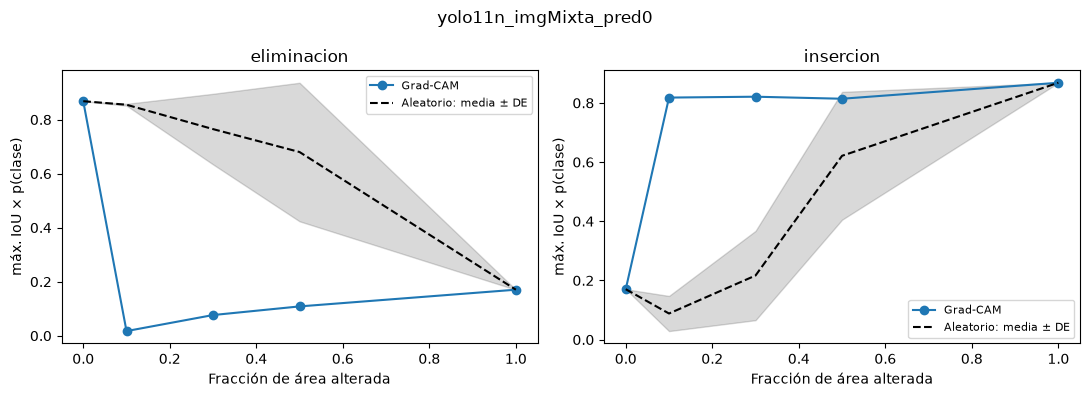

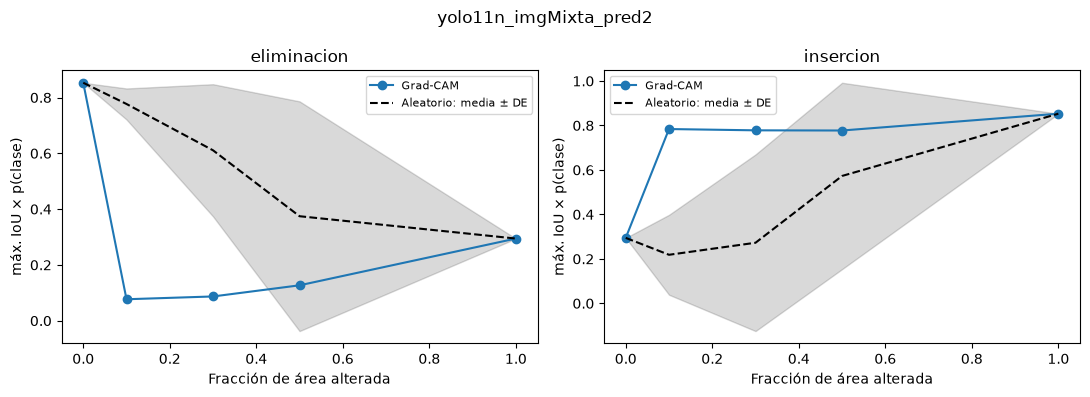

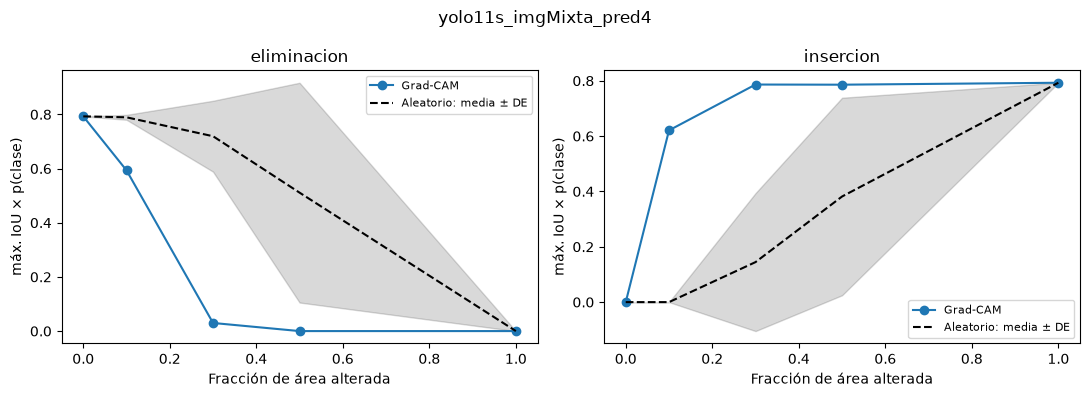

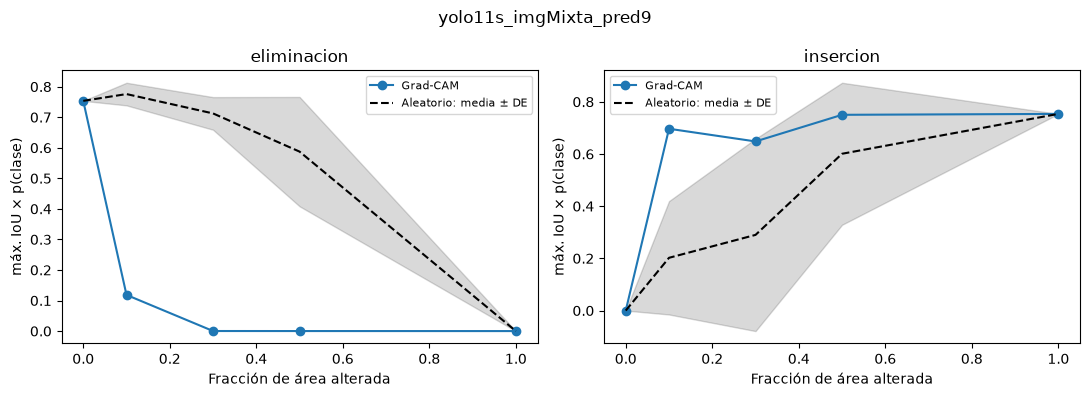

In [8]:
resumen = []
if len(curvas):
    for (caso, metodo, control, modo), datos in curvas.groupby(['caso', 'metodo', 'control', 'modo']):
        datos = datos.sort_values('area_real')
        original = curvas[(curvas.caso == caso) & (curvas.modo == 'eliminacion') &
                          (curvas.fraccion == 0)].score_reasociado.iloc[0]
        area = np.trapezoid(datos.score_reasociado, datos.area_real)
        resumen.append(dict(caso=caso, metodo=metodo, control=control, modo=modo,
                            auc=area, auc_normalizada=area / original if original > 0 else np.nan))
auc = pd.DataFrame(resumen)
if len(auc):
    controles = auc[auc.metodo == 'aleatorio'].groupby(['caso', 'modo']).auc_normalizada.agg(['mean', 'std'])
    controles = controles.rename(columns={'mean': 'media_aleatoria', 'std': 'de_aleatoria'})
    auc = auc.merge(controles, on=['caso', 'modo'])
    auc['diferencia_frente_aleatorio'] = auc.auc_normalizada - auc.media_aleatoria
    display(auc[auc.metodo == 'Grad-CAM'].round(4))

    for caso, datos in curvas.groupby('caso'):
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, modo in zip(axes, ('eliminacion', 'insercion')):
            sub = datos[datos.modo == modo]
            cam = sub[sub.metodo == 'Grad-CAM'].sort_values('area_real')
            aleatorio = sub[sub.metodo == 'aleatorio'].groupby('area_real').score_reasociado.agg(['mean', 'std'])
            ax.plot(cam.area_real, cam.score_reasociado, marker='o', label='Grad-CAM')
            ax.plot(aleatorio.index, aleatorio['mean'], '--', color='black', label='Aleatorio: media ± DE')
            ax.fill_between(aleatorio.index, aleatorio['mean'] - aleatorio['std'],
                            aleatorio['mean'] + aleatorio['std'], color='black', alpha=.15)
            ax.set(xlabel='Fracción de área alterada', ylabel='máx. IoU × p(clase)', title=modo)
            ax.legend(fontsize=8)
        fig.suptitle(caso)
        plt.tight_layout(); plt.show()

## 6. Experimentos opcionales: escena y contexto

Activa `EJECUTAR_ESCENA` para obtener el mapa de cada clase sobre todas las detecciones
de la escena. Se suman los logits de esa clase incluso en candidatas de otra clase;
es evidencia agregada, distinta de la explicación de un grano.

Activa `EJECUTAR_CONTEXTO` para comparar una imagen con otra donde se borra por inpainting
uno de los grupos de referencia. Se conservan los granos restantes y se emparejan de nuevo
las detecciones. Esta edición introduce artefactos: sirve como exploración del contexto,
no como prueba causal ni como nueva referencia sanitaria.

In [9]:
if EJECUTAR_ESCENA:
    for (modelo, escena), p in PREP.items():
        if not len(p['det']['indices']):
            continue
        niveles = sorted(set(p['det']['nivel']))
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        for ax, clase in zip(axes, (0, 1)):
            mapa = DET[modelo].mapa(p['x'], niveles, p['det']['indices'], clase, objetivo=OBJETIVO)
            vista(ax, K.superponer(p['rgb'], mapa), p, f'Escena · {CLASE[clase]}')
        fig.suptitle(f'{modelo} · {escena} · objetivo agregado')
        plt.tight_layout(); plt.show()
else:
    print('Mapas agregados desactivados; activa EJECUTAR_ESCENA para ejecutarlos.')

if EJECUTAR_CONTEXTO:
    comparacion_contexto = []
    for (modelo, escena), p in PREP.items():
        for borrar_clase in (0, 1):
            if not np.any(p['cl'] == borrar_clase):
                continue
            img = K.borrar(p['img'], K.cargar_foto(escena)[1][p['cl'] == borrar_clase])
            x, rgb, t = DET[modelo].preparar(img)
            det = DET[modelo].detectar(x)
            presentes = p['cl'] != borrar_clase
            filas = K.inventario(p['ref'][presentes], p['cl'][presentes], det)
            comparacion_contexto.extend({'modelo': modelo, 'escena': escena,
                                         'grupo_borrado': CLASE[borrar_clase], **r} for r in filas)
    display(pd.DataFrame(comparacion_contexto))
else:
    print('Inpainting desactivado; activa EJECUTAR_CONTEXTO para ejecutarlo.')

Mapas agregados desactivados; activa EJECUTAR_ESCENA para ejecutarlos.
Inpainting desactivado; activa EJECUTAR_CONTEXTO para ejecutarlo.


## 7. Prueba con imágenes de valid

Se seleccionan **tres imágenes al azar, sin reemplazo y con semilla 42**, a partir del
listado ordenado de `Data_final/valid/images`. La selección se realiza antes de evaluar
las predicciones. Cambia `N_VALID` y `SEMILLA_VALID` en la siguiente celda para ampliar la prueba.

Se mantienen los pesos, umbrales, objetivo y protocolo de perturbación del experimento
anterior. Cada imagen se evalúa con ambos modelos y conserva un inventario completo.
Para generar mapas se toma el primer acierto, el primer cambio de clase y el primer
sobrante, cuando existan. Se explica la clase predicha en el nivel P3/P4/P5 que produjo
la detección. Los no detectados se registran, sin atribuirles un CAM de una detección inexistente.

Este análisis es exploratorio; sus resultados no se utilizan para reajustar modelos,
umbrales ni capas. Las tablas y figuras quedan aquí, sin crear archivos adicionales.

In [10]:
N_VALID = 3
SEMILLA_VALID = 42
rutas_valid = sorted((K.E.FINAL / 'valid' / 'images').glob('*.jpg'))
if not rutas_valid:
    raise FileNotFoundError(f"No hay imágenes en {K.E.FINAL / 'valid' / 'images'}")
if not 1 <= N_VALID <= len(rutas_valid):
    raise ValueError(f'N_VALID debe estar entre 1 y {len(rutas_valid)}.')
indices_valid = np.sort(np.random.default_rng(SEMILLA_VALID).choice(len(rutas_valid), size=N_VALID, replace=False))
seleccion_valid = [rutas_valid[int(i)] for i in indices_valid]
# La selección depende solo del listado y la semilla, nunca del resultado del modelo.
assert len(set(seleccion_valid)) == N_VALID
print(f'Selección fija: {N_VALID} de {len(rutas_valid)} imágenes de valid, semilla {SEMILLA_VALID}')
for ruta in seleccion_valid:
    print(ruta.name)

PREP_VALID, CASOS_VALID, MAPAS_VALID = {}, [], {}
filas_valid, comparaciones_valid = [], []
manifiesto_valid = {'fecha': datetime.now(ZoneInfo('America/Guayaquil')).isoformat(),
                  'split': 'valid', 'versiones': manifiesto['versiones'],
                  'codigo_sha256': K.sha256(Path(K.__file__)),
                  'modelos': {m: manifiesto['modelos'][m] for m in MODELOS},
                  'seleccion': {'n': N_VALID, 'total': len(rutas_valid), 'semilla': SEMILLA_VALID,
                                'metodo': 'default_rng.choice sin reemplazo sobre listado ordenado',
                                'imagenes': [r.name for r in seleccion_valid]},
                  'protocolo': {'objetivo': OBJETIVO, 'fracciones': FRACCIONES,
                                'controles': ALEATORIOS, 'bloque': TAM_BLOQUE, 'sigma': SIGMA,
                                'semilla_controles': SEMILLA,
                                'capa': 'nivel que produjo la candidata'},
                  'imagenes': {}, 'casos': []}
for ruta in seleccion_valid:
    imagen_rgb, ref, cl, _ = K.E.cargar(ruta.stem, 'valid')
    img = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2BGR)
    manifiesto_valid['imagenes'][ruta.stem] = {
        'ruta': str(ruta), 'sha256': K.sha256(ruta),
        'referencia_sha256': K.sha256(K.E.FINAL / 'valid' / 'labels' / f'{ruta.stem}.txt')}
    for modelo in MODELOS:
        d = DET[modelo]
        x, rgb, t = d.preparar(img, preprocesada=True)
        det = d.detectar(x)
        refs = K.a_letterbox(ref, t)
        registros = K.inventario(refs, cl, det)
        PREP_VALID[modelo, ruta.stem] = dict(img=img, x=x, rgb=rgb, t=t, det=det,
                                           ref=refs, cl=cl, inventario=registros,
                                           dominio=K.dominio_imagen(rgb.shape[:2], img.shape[:2], t))
        filas_valid.extend({'modelo': modelo, 'imagen': ruta.stem, **r} for r in registros)
        r = YOLO(str(d.pesos)).predict(img, imgsz=d.imgsz, conf=d.conf, iou=d.iou,
                                       agnostic_nms=True, device=d.dispositivo, verbose=False)[0]
        otro = {'cajas': K.a_letterbox(r.boxes.xyxy.cpu().numpy(), t),
                'clases': r.boxes.cls.cpu().numpy().astype(int), 'conf': r.boxes.conf.cpu().numpy()}
        comparaciones_valid.append({'modelo': modelo, 'imagen': ruta.stem,
                                   **K.comparar_detecciones(det, otro)})
        for estado in ('acierto', 'clase cambiada', 'sobrante'):
            registro = next((r for r in registros if r['estado'] == estado), None)
            if registro is None:
                continue
            q = registro['prediccion']
            CASOS_VALID.append(dict(modelo=modelo, imagen=ruta.stem, **registro,
                                   id=f'valid_{modelo}_{ruta.stem}_pred{q}', indice=int(det['indices'][q]),
                                   clase=int(det['clases'][q]), capa=str(det['nivel'][q]),
                                   caja=det['cajas'][q].tolist(), forma_tensor=list(x.shape)))
manifiesto_valid['casos'] = CASOS_VALID
inventario_valid = pd.DataFrame(filas_valid)
comparacion_predict_valid = pd.DataFrame(comparaciones_valid)
display(comparacion_predict_valid)
display(inventario_valid.groupby(['modelo', 'imagen', 'estado']).size().rename('n').to_frame())
print('Casos seleccionados para los mapas:', len(CASOS_VALID))
display(JSON(manifiesto_valid, expanded=False))

Selección fija: 3 de 115 imágenes de valid, semilla 42
20220510_104222_jpg.rf.d6e3b97d44a83ef16be5926cbdd1c399.jpg
IMG_20220601_111220_jpg.rf.507d3a5e875fc72b88bd7df29d1314d7.jpg
IMG_20220601_113150_jpg.rf.5d3397c0c75ca4cd4795b5ae27d9558e.jpg


,modelo,imagen,parejas,sin_pareja_a,sin_pareja_b,mismas_clases_pareadas,min_iou,max_diferencia_caja_px,max_diferencia_conf,equivalentes
0,yolo11n,20220510_104222_jpg.rf.d6e3b97d44a83ef16be5926...,50,0,0,True,0.999875,0.003632,0.001204,False
1,yolo11s,20220510_104222_jpg.rf.d6e3b97d44a83ef16be5926...,50,0,0,True,0.999871,0.005066,0.000969,False
2,yolo11n,IMG_20220601_111220_jpg.rf.507d3a5e875fc72b88b...,30,0,0,True,0.999828,0.004517,0.000490,False
3,yolo11s,IMG_20220601_111220_jpg.rf.507d3a5e875fc72b88b...,30,0,0,True,0.999885,0.002258,0.000245,False
4,yolo11n,IMG_20220601_113150_jpg.rf.5d3397c0c75ca4cd479...,30,0,0,True,0.999841,0.006714,0.000468,False
5,yolo11s,IMG_20220601_113150_jpg.rf.5d3397c0c75ca4cd479...,30,0,0,True,0.988605,0.476715,0.000332,False


n
modelo  imagen                                             estado            
yolo11n 20220510_104222_jpg.rf.d6e3b97d44a83ef16be5926c... acierto         50
        IMG_20220601_111220_jpg.rf.507d3a5e875fc72b88bd... acierto         30
        IMG_20220601_113150_jpg.rf.5d3397c0c75ca4cd4795... acierto         30
yolo11s 20220510_104222_jpg.rf.d6e3b97d44a83ef16be5926c... clase cambiada  50
        IMG_20220601_111220_jpg.rf.507d3a5e875fc72b88bd... acierto         30
        IMG_20220601_113150_jpg.rf.5d3397c0c75ca4cd4795... acierto         30

Casos seleccionados para los mapas: 6


<IPython.core.display.JSON object>

### Mapas de Grad-CAM y concentración en valid

El recuadro blanco señala la caja predicha que se explica; el título muestra su clase
de referencia y su clase predicha. Se calcula el mapa sobre la imagen completa.
La concentración se mide respecto a las cajas de referencia; para un sobrante se usa
su caja predicha y se indica expresamente. El fondo se contrasta con el área uniforme.

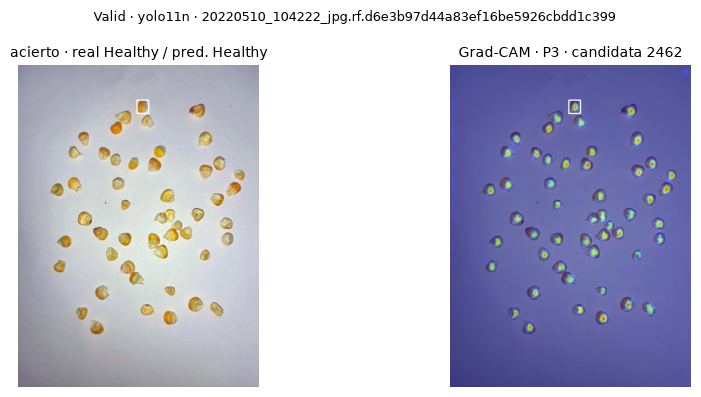

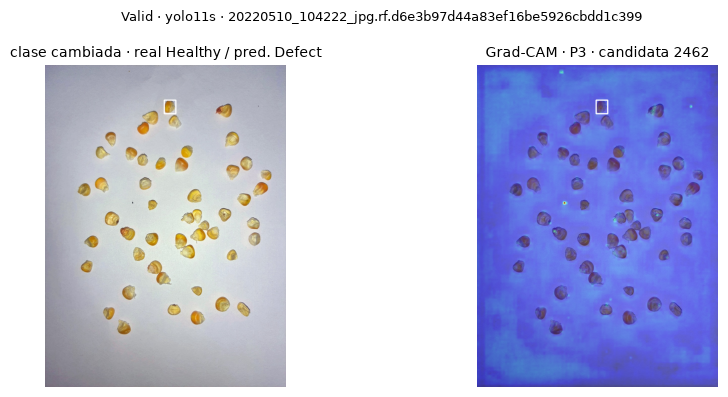

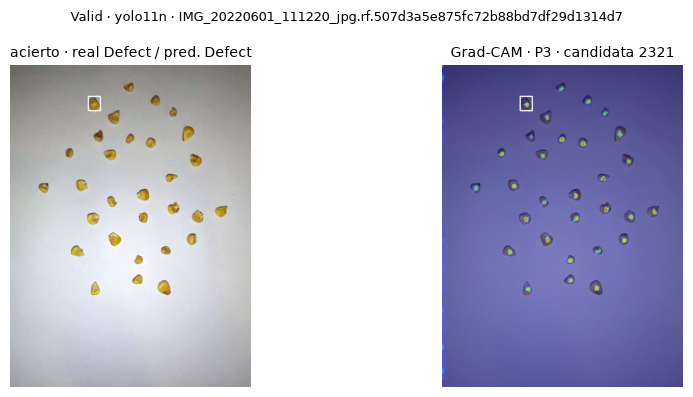

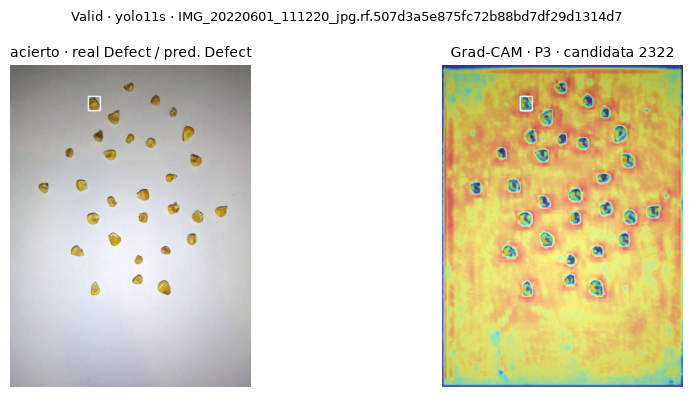

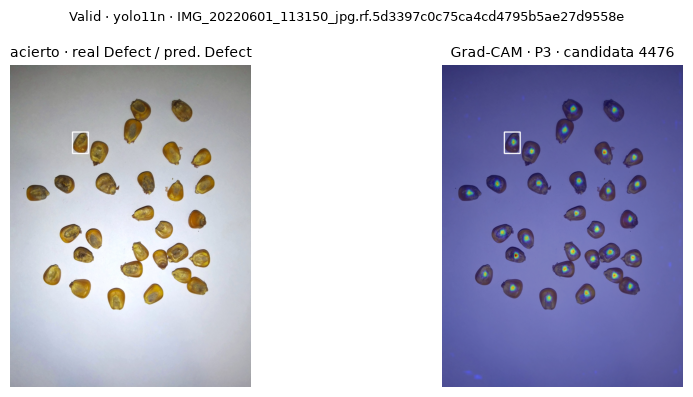

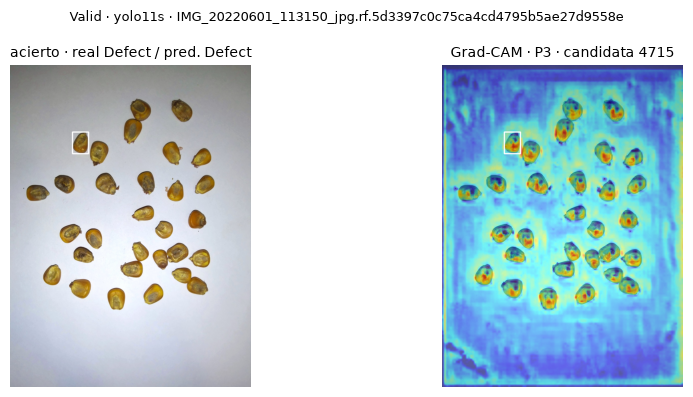

,caso,estado,capa,cajas,mapa_plano,propia,area_propia,enriquecimiento_propia,misma clase,area_misma clase,enriquecimiento_misma clase,otra clase,area_otra clase,enriquecimiento_otra clase,fondo,area_fondo,enriquecimiento_fondo
0,valid_yolo11n_20220510_104222_jpg.rf.d6e3b97d4...,acierto,P3,referencia,False,0.02006,0.00262,7.64386,0.95534,0.14663,6.51539,0.0,0.0,NaN,0.02460,0.85075,0.02892
1,valid_yolo11s_20220510_104222_jpg.rf.d6e3b97d4...,clase cambiada,P3,referencia,False,0.00233,0.00262,0.88660,0.11655,0.14663,0.79487,0.0,0.0,NaN,0.88112,0.85075,1.03570
2,valid_yolo11n_IMG_20220601_111220_jpg.rf.507d3...,acierto,P3,referencia,False,0.03293,0.00212,15.50216,0.84919,0.04998,16.99146,0.0,0.0,NaN,0.11789,0.94790,0.12437
3,valid_yolo11s_IMG_20220601_111220_jpg.rf.507d3...,acierto,P3,referencia,False,0.00141,0.00212,0.66502,0.02987,0.04998,0.59766,0.0,0.0,NaN,0.96872,0.94790,1.02196
4,valid_yolo11n_IMG_20220601_113150_jpg.rf.5d339...,acierto,P3,referencia,False,0.03001,0.00469,6.40205,0.92824,0.13898,6.67886,0.0,0.0,NaN,0.04176,0.85633,0.04876
5,valid_yolo11s_IMG_20220601_113150_jpg.rf.5d339...,acierto,P3,referencia,False,0.00704,0.00469,1.50169,0.18697,0.13898,1.34529,0.0,0.0,NaN,0.80599,0.85633,0.94121


In [11]:
concentraciones_valid = []
for (modelo, imagen), p in PREP_VALID.items():
    casos_imagen = [c for c in CASOS_VALID if c['modelo'] == modelo and c['imagen'] == imagen]
    if not casos_imagen:
        print(modelo, imagen, ': sin detecciones seleccionadas; consultar inventario_valid.')
        continue
    fig, axes = plt.subplots(len(casos_imagen), 2, figsize=(10, 4 * len(casos_imagen)), squeeze=False)
    for fila, caso in zip(axes, casos_imagen):
        mapa = DET[modelo].mapa(p['x'], [caso['capa']], [caso['indice']], caso['clase'], objetivo=OBJETIVO)
        assert np.isfinite(mapa).all() and (mapa >= 0).all()
        MAPAS_VALID[caso['id']] = mapa
        caja = np.asarray(caso['caja'])[None]
        real = 'sin referencia' if caso['referencia'] is None else CLASE[caso['referencia']]
        vista(fila[0], K.E.dibujar(p['rgb'], caja, (255, 255, 255), 3), p,
              f"{caso['estado']} · real {real} / pred. {CLASE[caso['clase']]}", recortar=False)
        vista(fila[1], K.E.dibujar(K.superponer(p['rgb'], mapa), caja, (255, 255, 255), 3), p,
              f"Grad-CAM · {caso['capa']} · candidata {caso['indice']}", recortar=False)
        g = caso['grano']
        cajas, clases, gi = ((p['ref'], p['cl'], g) if g is not None
                             else (caja, np.array([caso['clase']]), 0))
        concentraciones_valid.append({'caso': caso['id'], 'estado': caso['estado'], 'capa': caso['capa'],
                                     'cajas': 'referencia' if g is not None else 'predichas',
                                     'mapa_plano': bool(np.ptp(mapa) < 1e-7),
                                     **K.concentracion(mapa, cajas, clases, gi, p['dominio'])})
    fig.suptitle(f'Valid · {modelo} · {imagen}', fontsize=9)
    plt.tight_layout(); plt.show()
concentracion_valid = pd.DataFrame(concentraciones_valid)
display(concentracion_valid.round(5))

### Eliminación e inserción en valid

Se aplica a los casos anteriores el mismo protocolo de bloques, desenfoque, áreas y
tres controles aleatorios del experimento con fotos propias. Las variables de valid
se guardan aparte para conservar ambos análisis. Estas curvas no representan una
evaluación de todas las detecciones del conjunto valid.

In [12]:
resultados_valid = []
for caso in CASOS_VALID:
    p = PREP_VALID[caso['modelo'], caso['imagen']]
    tabla = K.perturbaciones(DET[caso['modelo']], p['x'], p['rgb'], p['dominio'], caso,
                             MAPAS_VALID[caso['id']], fracciones=FRACCIONES, aleatorios=ALEATORIOS,
                             tam_bloque=TAM_BLOQUE, sigma=SIGMA, semilla=SEMILLA)
    tabla.insert(0, 'caso', caso['id'])
    resultados_valid.append(tabla)
    print('Completado:', caso['modelo'], caso['imagen'], caso['estado'])
curvas_valid = pd.concat(resultados_valid, ignore_index=True) if resultados_valid else pd.DataFrame()
if len(curvas_valid):
    assert curvas_valid.groupby(['caso', 'fraccion']).area_real.nunique().eq(1).all()
    assert np.isfinite(curvas_valid.select_dtypes('number')).all().all()
    for _, grupo in curvas_valid.groupby('caso'):
        original = grupo[((grupo.modo == 'eliminacion') & (grupo.fraccion == 0)) |
                         ((grupo.modo == 'insercion') & (grupo.fraccion == 1))]
        base = grupo[((grupo.modo == 'insercion') & (grupo.fraccion == 0)) |
                     ((grupo.modo == 'eliminacion') & (grupo.fraccion == 1))]
        assert original.score_reasociado.nunique() == 1 and base.score_reasociado.nunique() == 1
    print(len(curvas_valid), 'mediciones de valid; igualdad de área, finitud y extremos: OK')
else:
    print('Sin casos de detección para las perturbaciones; consultar inventario_valid.')

resumen_valid = []
if len(curvas_valid):
    for (caso, metodo, control, modo), datos in curvas_valid.groupby(['caso', 'metodo', 'control', 'modo']):
        datos = datos.sort_values('area_real')
        original = curvas_valid[(curvas_valid.caso == caso) & (curvas_valid.modo == 'eliminacion') &
                               (curvas_valid.fraccion == 0)].score_reasociado.iloc[0]
        area = np.trapezoid(datos.score_reasociado, datos.area_real)
        resumen_valid.append(dict(caso=caso, metodo=metodo, control=control, modo=modo,
                                 auc=area, auc_normalizada=area / original if original > 0 else np.nan))
auc_valid = pd.DataFrame(resumen_valid)
if len(auc_valid):
    controles_valid = auc_valid[auc_valid.metodo == 'aleatorio'].groupby(['caso', 'modo']).auc_normalizada.agg(['mean', 'std'])
    controles_valid = controles_valid.rename(columns={'mean': 'media_aleatoria', 'std': 'de_aleatoria'})
    auc_valid = auc_valid.merge(controles_valid, on=['caso', 'modo'])
    auc_valid['diferencia_frente_aleatorio'] = auc_valid.auc_normalizada - auc_valid.media_aleatoria
    display(auc_valid[auc_valid.metodo == 'Grad-CAM'].round(4))

Completado: yolo11n 20220510_104222_jpg.rf.d6e3b97d44a83ef16be5926cbdd1c399 acierto


Completado: yolo11s 20220510_104222_jpg.rf.d6e3b97d44a83ef16be5926cbdd1c399 clase cambiada


Completado: yolo11n IMG_20220601_111220_jpg.rf.507d3a5e875fc72b88bd7df29d1314d7 acierto


Completado: yolo11s IMG_20220601_111220_jpg.rf.507d3a5e875fc72b88bd7df29d1314d7 acierto


Completado: yolo11n IMG_20220601_113150_jpg.rf.5d3397c0c75ca4cd4795b5ae27d9558e acierto


Completado: yolo11s IMG_20220601_113150_jpg.rf.5d3397c0c75ca4cd4795b5ae27d9558e acierto
240 mediciones de valid; igualdad de área, finitud y extremos: OK


,caso,metodo,control,modo,auc,auc_normalizada,media_aleatoria,de_aleatoria,diferencia_frente_aleatorio
0,valid_yolo11n_20220510_104222_jpg.rf.d6e3b97d4...,Grad-CAM,-1,eliminacion,0.1991,0.2307,0.4822,0.0673,-0.2515
1,valid_yolo11n_20220510_104222_jpg.rf.d6e3b97d4...,Grad-CAM,-1,insercion,0.7148,0.8281,0.5093,0.0622,0.3187
8,valid_yolo11n_IMG_20220601_111220_jpg.rf.507d3...,Grad-CAM,-1,eliminacion,0.3848,0.4452,0.7292,0.1016,-0.2840
9,valid_yolo11n_IMG_20220601_111220_jpg.rf.507d3...,Grad-CAM,-1,insercion,0.7802,0.9026,0.7804,0.0658,0.1222
16,valid_yolo11n_IMG_20220601_113150_jpg.rf.5d339...,Grad-CAM,-1,eliminacion,0.1810,0.2027,0.4507,0.0422,-0.2480
17,valid_yolo11n_IMG_20220601_113150_jpg.rf.5d339...,Grad-CAM,-1,insercion,0.7586,0.8495,0.4516,0.1881,0.3979
24,valid_yolo11s_20220510_104222_jpg.rf.d6e3b97d4...,Grad-CAM,-1,eliminacion,0.5261,0.7740,0.4284,0.0539,0.3456
25,valid_yolo11s_20220510_104222_jpg.rf.d6e3b97d4...,Grad-CAM,-1,insercion,0.1748,0.2572,0.5753,0.0036,-0.3181
32,valid_yolo11s_IMG_20220601_111220_jpg.rf.507d3...,Grad-CAM,-1,eliminacion,0.5083,0.6070,0.5870,0.1524,0.0200
33,valid_yolo11s_IMG_20220601_111220_jpg.rf.507d3...,Grad-CAM,-1,insercion,0.5190,0.6198,0.6027,0.3055,0.0172


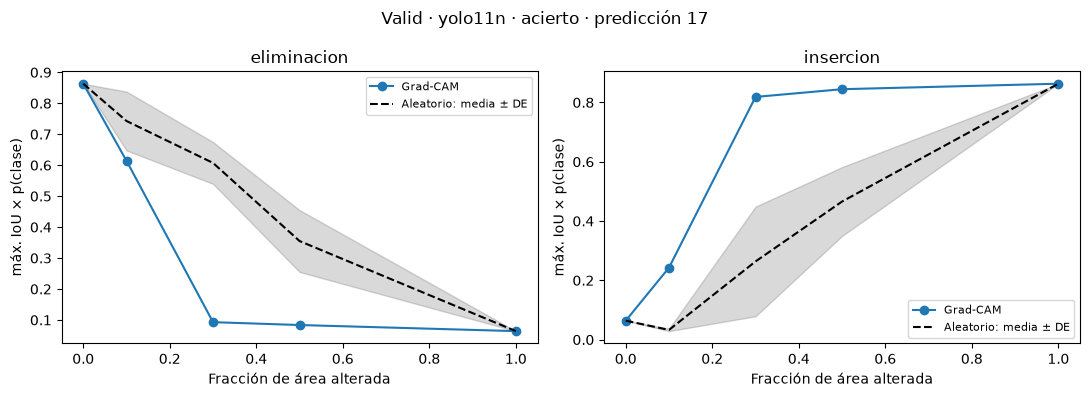

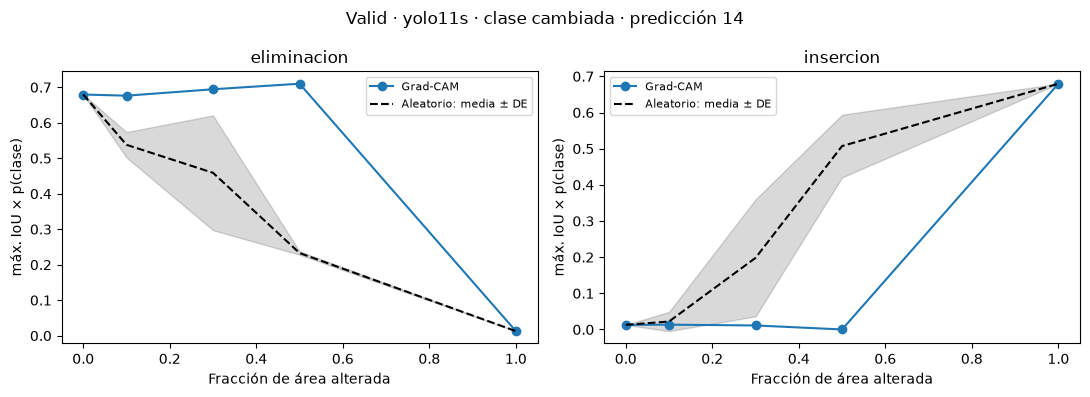

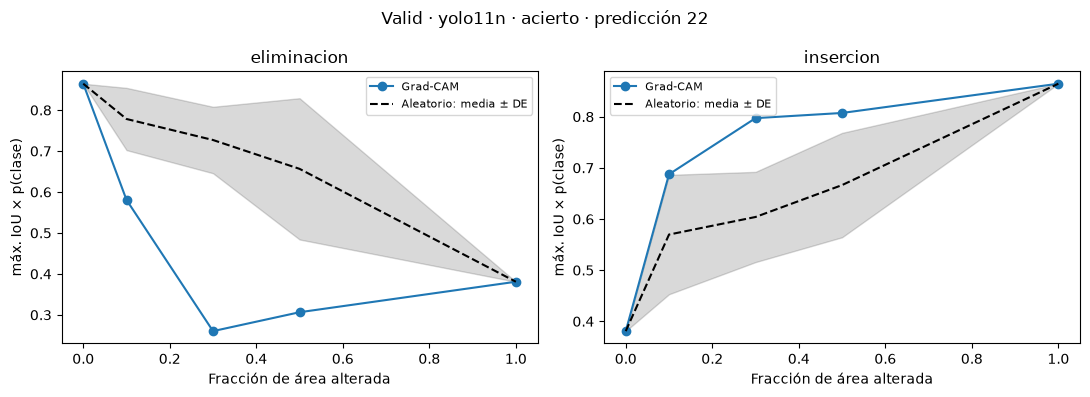

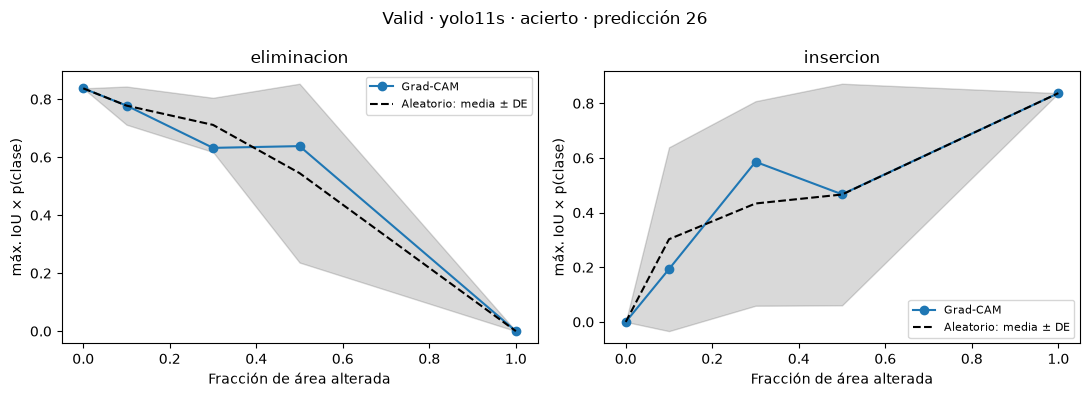

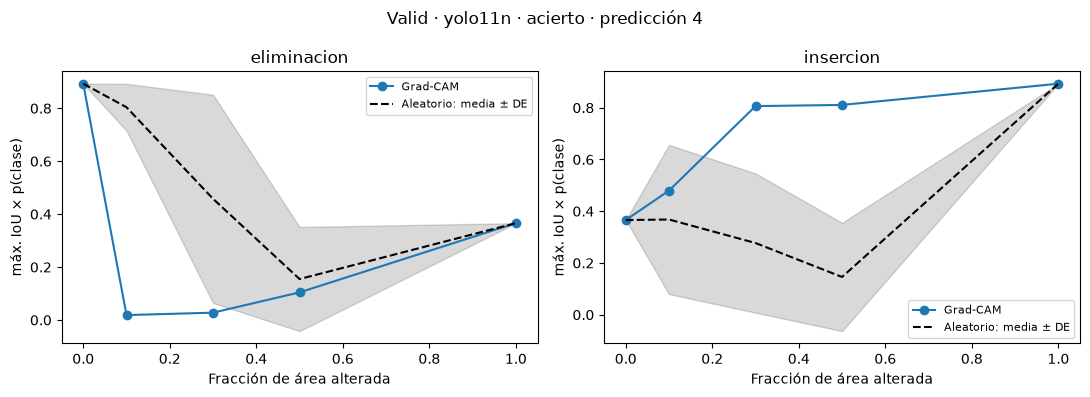

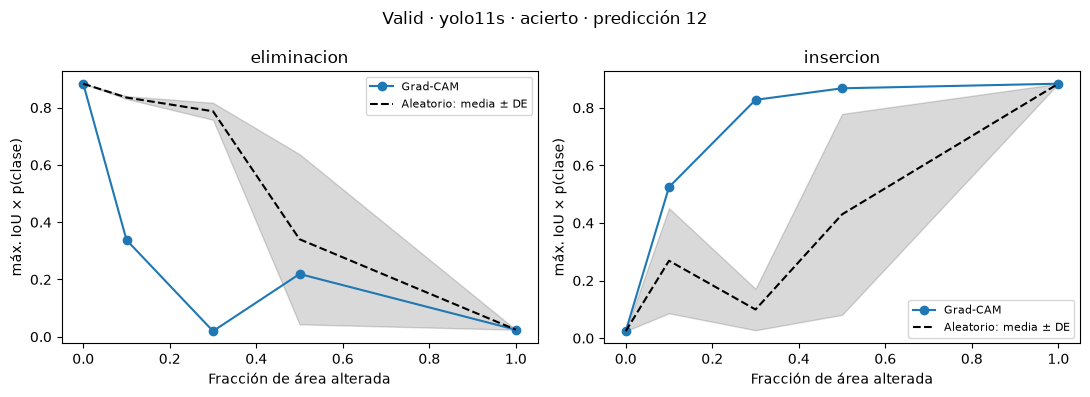

In [13]:
if len(curvas_valid):
    for caso in CASOS_VALID:
        datos = curvas_valid[curvas_valid.caso == caso['id']]
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, modo in zip(axes, ('eliminacion', 'insercion')):
            sub = datos[datos.modo == modo]
            cam = sub[sub.metodo == 'Grad-CAM'].sort_values('area_real')
            aleatorio = sub[sub.metodo == 'aleatorio'].groupby('area_real').score_reasociado.agg(['mean', 'std'])
            ax.plot(cam.area_real, cam.score_reasociado, marker='o', label='Grad-CAM')
            ax.plot(aleatorio.index, aleatorio['mean'], '--', color='black', label='Aleatorio: media ± DE')
            ax.fill_between(aleatorio.index, aleatorio['mean'] - aleatorio['std'],
                            aleatorio['mean'] + aleatorio['std'], color='black', alpha=.15)
            ax.set(xlabel='Fracción de área alterada', ylabel='máx. IoU × p(clase)', title=modo)
            ax.legend(fontsize=8)
        fig.suptitle(f"Valid · {caso['modelo']} · {caso['estado']} · predicción {caso['prediccion']}")
        plt.tight_layout(); plt.show()

## Interpretación

- Menor AUC de eliminación y mayor AUC de inserción indican mayor sensibilidad/recuperación
  bajo este protocolo. La AUC normalizada puede superar 1 si la perturbación aumenta la puntuación.
- La energía en una caja no es el porcentaje de una decisión. Un mapa localizado puede acompañar
  un error de clase; un mapa disperso no demuestra por sí solo un gradiente mal conectado.
- La perturbación y el indicador reasociado tienen límites. Estos experimentos en fotos propias y en una muestra de valid no
  demuestra causalidad ni superioridad universal, y no valida el conteo final.
- Para ampliar el análisis, fija de antemano más imágenes/casos, fracciones y controles.
  Conserva juntos aciertos, errores e inventario. Las tablas completas siguen disponibles
  en `inventario`, `comparacion_predict`, `concentracion`, `curvas`, `auc` y `manifiesto`.
- Los datos de valid se conservan aparte en `inventario_valid`, `comparacion_predict_valid`,
  `concentracion_valid`, `curvas_valid`, `auc_valid` y `manifiesto_valid`.